# 01. Global Air Pollution AQI Category Classification & Machine Learning Pipeline

## Project Goal
This notebook implements the historical machine learning phase for the project:
**"A Live Web-Scraped Dashboard for Aggregating and Analyzing Global Air Pollution Violations and Pollutant Exceedances"**

The objective is to train, evaluate, tune, and serialize a robust Machine Learning model to predict the overall **`aqi_category`** based on numerical pollutant AQI values (`co_aqi_value`, `ozone_aqi_value`, `no2_aqi_value`, `pm2.5_aqi_value`), engineered pollutant interaction features, and location information (`country_name`).

### Scientific Limitation Notice
> **IMPORTANT:** This model predicts the **AQI Category** based on historical atmospheric air-quality measurements. It **DOES NOT** directly predict legal environmental regulatory violations. An air-quality exceedance is not necessarily equivalent to a regulatory enforcement violation. The future live phase will combine this trained ML model with actual regulatory enforcement records and web-scraped compliance data.


## 2. Environment & Module Imports
Loading essential Python scientific computing, data manipulation, visualization, scikit-learn machine learning, and serialization libraries.


In [1]:
import os
import json
import joblib
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# Machine Learning Classifiers
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, HistGradientBoostingClassifier,
    ExtraTreesClassifier, GradientBoostingClassifier
)

# Plotting settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

print("All dependencies successfully imported!")


All dependencies successfully imported!


## 3. Global Configuration & Paths
Defining relative file paths, directories, target variables, and random seeds to guarantee 100% reproducible execution without hardcoded absolute machine paths.


In [2]:
DATASET_PATH = Path("global_air_pollution_data.csv")
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_FILE = MODELS_DIR / "air_quality_aqi_category_model.joblib"
METADATA_FILE = MODELS_DIR / "model_metadata.json"

TARGET_COL = "aqi_category"
RANDOM_STATE = 42
TEST_SIZE = 0.20

print(f"Dataset path: {DATASET_PATH.resolve()}")
print(f"Models directory: {MODELS_DIR.resolve()}")


Dataset path: C:\Users\vimal\OneDrive\Desktop\Data sciencee\global_air_pollution_data.csv
Models directory: C:\Users\vimal\OneDrive\Desktop\Data sciencee\models


## 4. Load Dataset
Loading `global_air_pollution_data.csv` using `pandas.read_csv`.


In [3]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATASET_PATH}. Ensure the file exists in the directory.")

df_raw = pd.read_csv(DATASET_PATH)
print(f"Successfully loaded dataset with shape: {df_raw.shape}")


Successfully loaded dataset with shape: (23463, 12)


## 5. Comprehensive Dataset Inspection
Inspecting raw dataset characteristics:
1. Shape
2. Head & Tail rows
3. Column names (checking for whitespace issues)
4. Data types & Info
5. Missing-value counts
6. Duplicate-row counts
7. Descriptive statistics
8. Target class distribution


In [4]:
print("--- 1. DATASET SHAPE ---")
print(df_raw.shape)

print("\n--- 2. FIRST 10 ROWS ---")
display(df_raw.head(10))

print("\n--- 3. LAST 10 ROWS ---")
display(df_raw.tail(10))

print("\n--- 4. RAW COLUMN NAMES ---")
print([repr(col) for col in df_raw.columns])

print("\n--- 5. DATA TYPES & INFO ---")
df_raw.info()

print("\n--- 6. MISSING VALUES PER COLUMN ---")
print(df_raw.isnull().sum())

print("\n--- 7. DUPLICATE ROW COUNT ---")
print(f"Total duplicate rows: {df_raw.duplicated().sum()}")

print("\n--- 8. NUMERICAL DESCRIPTIVE STATISTICS ---")
display(df_raw.describe().T)

print("\n--- 9. TARGET DISTRIBUTION ---")
print(df_raw[TARGET_COL].value_counts(dropna=False))


--- 1. DATASET SHAPE ---
(23463, 12)

--- 2. FIRST 10 ROWS ---


,country_name,city_name,aqi_value,aqi_category,co_aqi_value\t,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2.5_aqi_value,pm2.5_aqi_category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good
5,United States of America,Punta Gorda,54,Moderate,1,Good,14,Good,11,Good,54,Moderate
6,Germany,Puttlingen,62,Moderate,1,Good,35,Good,3,Good,62,Moderate
7,Belgium,Puurs,64,Moderate,1,Good,29,Good,7,Good,64,Moderate
8,Russian Federation,Pyatigorsk,54,Moderate,1,Good,41,Good,1,Good,54,Moderate
9,Egypt,Qalyub,142,Unhealthy for Sensitive Groups,3,Good,89,Moderate,9,Good,142,Unhealthy for Sensitive Groups



--- 3. LAST 10 ROWS ---


,country_name,city_name,aqi_value,aqi_category,co_aqi_value\t,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2.5_aqi_value,pm2.5_aqi_category
23453,United Kingdom of Great Britain and Northern I...,Urmston,33,Good,1,Good,30,Good,3,Good,33,Good
23454,India,Konnur,86,Moderate,0,Good,23,Good,0,Good,86,Moderate
23455,China,Shaoguan,160,Unhealthy,3,Good,160,Unhealthy,1,Good,79,Moderate
23456,United States of America,Highland Springs,54,Moderate,1,Good,34,Good,5,Good,54,Moderate
23457,Slovakia,Martin,71,Moderate,1,Good,39,Good,1,Good,71,Moderate
23458,India,Gursahaiganj,184,Unhealthy,3,Good,154,Unhealthy,2,Good,184,Unhealthy
23459,France,Sceaux,50,Good,1,Good,20,Good,5,Good,50,Good
23460,India,Mormugao,50,Good,1,Good,22,Good,1,Good,50,Good
23461,United States of America,Westerville,71,Moderate,1,Good,44,Good,2,Good,71,Moderate
23462,Malaysia,Marang,70,Moderate,1,Good,38,Good,0,Good,70,Moderate



--- 4. RAW COLUMN NAMES ---
["'country_name'", "'city_name'", "'aqi_value'", "'aqi_category'", "'co_aqi_value\\t'", "'co_aqi_category'", "'ozone_aqi_value'", "'ozone_aqi_category'", "'no2_aqi_value'", "'no2_aqi_category'", "'pm2.5_aqi_value'", "'pm2.5_aqi_category'"]

--- 5. DATA TYPES & INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   country_name        23036 non-null  object
 1   city_name           23462 non-null  object
 2   aqi_value           23463 non-null  int64 
 3   aqi_category        23463 non-null  object
 4   co_aqi_value	       23463 non-null  int64 
 5   co_aqi_category     23463 non-null  object
 6   ozone_aqi_value     23463 non-null  int64 
 7   ozone_aqi_category  23463 non-null  object
 8   no2_aqi_value       23463 non-null  int64 
 9   no2_aqi_category    23463 non-null  object
 10  pm2.5_aqi_v

,count,mean,std,min,25%,50%,75%,max
aqi_value,23463.0,72.010868,56.055220,6.0,39.0,55.0,79.0,500.0
co_aqi_value\t,23463.0,1.368367,1.832064,0.0,1.0,1.0,1.0,133.0
ozone_aqi_value,23463.0,35.193709,28.098723,0.0,21.0,31.0,40.0,235.0
no2_aqi_value,23463.0,3.063334,5.254108,0.0,0.0,1.0,4.0,91.0
pm2.5_aqi_value,23463.0,68.519755,54.796443,0.0,35.0,54.0,79.0,500.0



--- 9. TARGET DISTRIBUTION ---
aqi_category
Good                              9936
Moderate                          9231
Unhealthy                         2227
Unhealthy for Sensitive Groups    1591
Very Unhealthy                     287
Hazardous                          191
Name: count, dtype: int64


## 6. Data Quality Analysis & Verification
Checking dataset integrity:
- Column header whitespace (e.g. `'co_aqi_value\t'`)
- Range validation for numerical pollutant AQI values (detecting negative or infinite values)
- Inconsistent string spaces or casing in categorical fields
- Unexpected target categories


In [5]:
# Fix trailing tab/space in column headers
df_clean = df_raw.copy()
df_clean.columns = df_clean.columns.str.strip()

print("Cleaned column names:")
print(list(df_clean.columns))

# Verify numerical pollutant ranges
num_cols_raw = [c for c in df_clean.columns if "value" in c]
print("\nNumerical Pollutant Value Summary:")
for c in num_cols_raw:
    min_val = df_clean[c].min()
    max_val = df_clean[c].max()
    neg_count = (df_clean[c] < 0).sum()
    inf_count = np.isinf(df_clean[c]).sum()
    print(f" - {c:20s}: Min={min_val:5d}, Max={max_val:5d}, Negative Count={neg_count}, Infinite Count={inf_count}")


Cleaned column names:
['country_name', 'city_name', 'aqi_value', 'aqi_category', 'co_aqi_value', 'co_aqi_category', 'ozone_aqi_value', 'ozone_aqi_category', 'no2_aqi_value', 'no2_aqi_category', 'pm2.5_aqi_value', 'pm2.5_aqi_category']

Numerical Pollutant Value Summary:
 - aqi_value           : Min=    6, Max=  500, Negative Count=0, Infinite Count=0
 - co_aqi_value        : Min=    0, Max=  133, Negative Count=0, Infinite Count=0
 - ozone_aqi_value     : Min=    0, Max=  235, Negative Count=0, Infinite Count=0
 - no2_aqi_value       : Min=    0, Max=   91, Negative Count=0, Infinite Count=0
 - pm2.5_aqi_value     : Min=    0, Max=  500, Negative Count=0, Infinite Count=0


## 7. Data Cleaning Strategy
- **Header Normalization**: Stripped trailing tab from `co_aqi_value\t`.
- **Categorical Trimming**: Stripped leading/trailing spaces from text columns (`country_name`, `city_name`, `aqi_category`).
- **Missing Values**: Handled in modeling pipeline using `SimpleImputer` to prevent premature data leakage.
- **Cardinatily Analysis (`city_name`)**: Checked unique count to evaluate utility.


In [6]:
# Clean string values
string_cols = df_clean.select_dtypes(include=["object"]).columns
for col in string_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Replace literal 'nan' strings with actual np.nan
df_clean.replace({"nan": np.nan, "None": np.nan, "": np.nan}, inplace=True)

print("Unique values per categorical column:")
print(f"country_name : {df_clean['country_name'].nunique(dropna=False)} unique countries (Missing: {df_clean['country_name'].isnull().sum()})")
print(f"city_name    : {df_clean['city_name'].nunique(dropna=False)} unique cities (Missing: {df_clean['city_name'].isnull().sum()})")
print(f"aqi_category : {df_clean['aqi_category'].nunique(dropna=False)} unique classes")


Unique values per categorical column:
country_name : 176 unique countries (Missing: 427)
city_name    : 23463 unique cities (Missing: 1)
aqi_category : 6 unique classes


## 8. Target Class Distribution Analysis
Analyzing the distribution of **`aqi_category`** to understand class balance.


--- TARGET CLASS DISTRIBUTION ---


,Sample Count,Percentage (%)
aqi_category,,
Good,9936,42.35
Moderate,9231,39.34
Unhealthy,2227,9.49
Unhealthy for Sensitive Groups,1591,6.78
Very Unhealthy,287,1.22
Hazardous,191,0.81


C:\Users\vimal\AppData\Local\Temp\ipykernel_21888\569583107.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=target_counts.index, y=target_counts.values, palette="Blues_r")


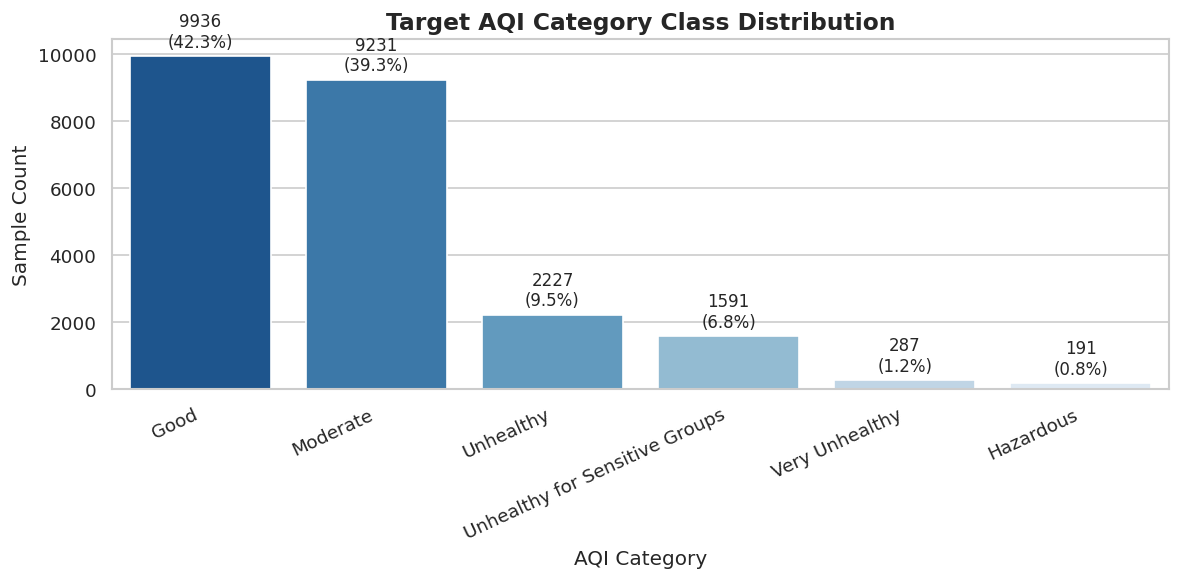

In [7]:
target_counts = df_clean[TARGET_COL].value_counts()
target_percentages = df_clean[TARGET_COL].value_counts(normalize=True) * 100

target_df = pd.DataFrame({
    'Sample Count': target_counts,
    'Percentage (%)': target_percentages.round(2)
})

print("--- TARGET CLASS DISTRIBUTION ---")
display(target_df)

# Plot class distribution
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=target_counts.index, y=target_counts.values, palette="Blues_r")
plt.title("Target AQI Category Class Distribution", fontsize=14, fontweight="bold")
plt.xlabel("AQI Category", fontsize=12)
plt.ylabel("Sample Count", fontsize=12)
plt.xticks(rotation=25, ha="right")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df_clean)*100:.1f}%)", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


### Interpretation of Target Distribution
- **Class Imbalance Detected**: The dataset is imbalanced. `Good` (42.4%) and `Moderate` (39.3%) constitute ~81.7% of all samples, whereas minority classes like `Very Unhealthy` (1.2%) and `Hazardous` (0.8%) have significantly fewer samples.
- **Handling Strategy**: We must use **stratified train/test splitting** and **Stratified K-Fold cross-validation** to maintain class proportions across splits. Furthermore, we evaluate models using **Macro F1** and **Balanced Accuracy** in addition to overall accuracy, and utilize `class_weight='balanced'` for cost-sensitive models.


## 9. Exploratory Data Analysis (EDA)
Generating visualizations to understand feature distributions and pollutant-target relationships.


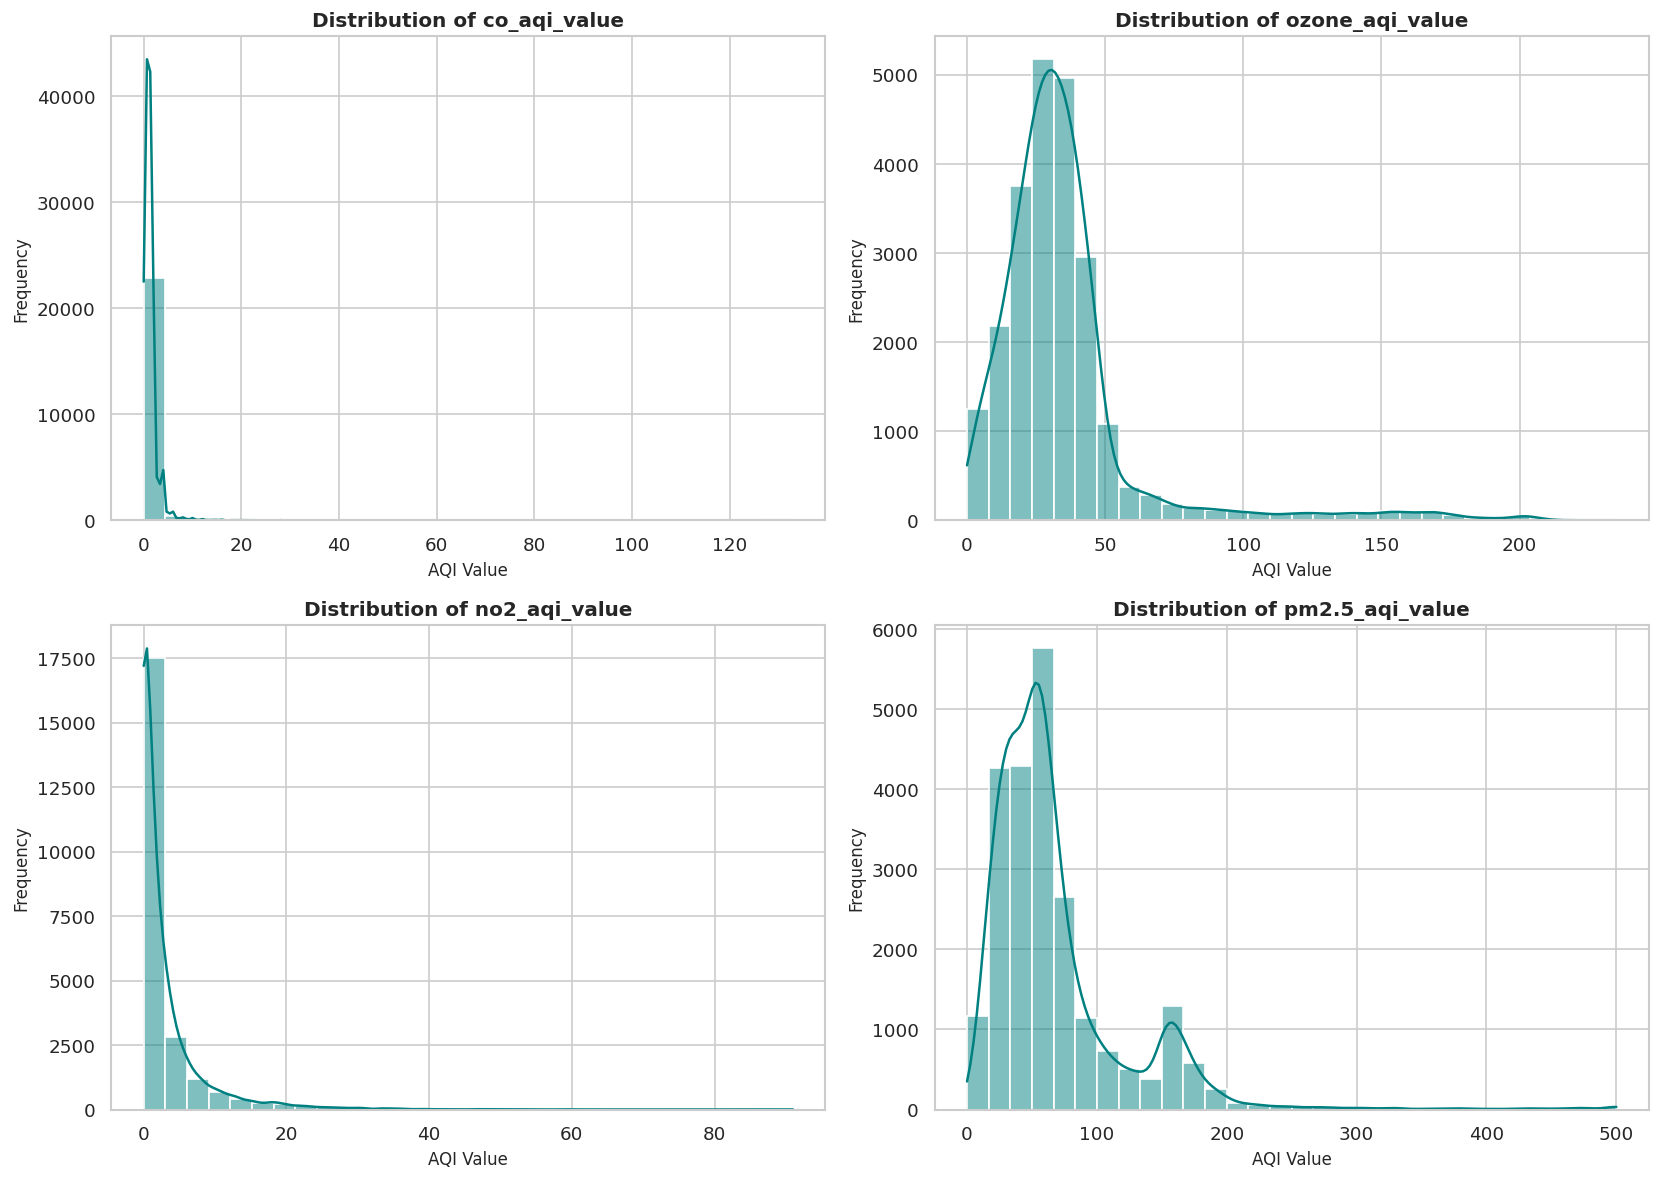

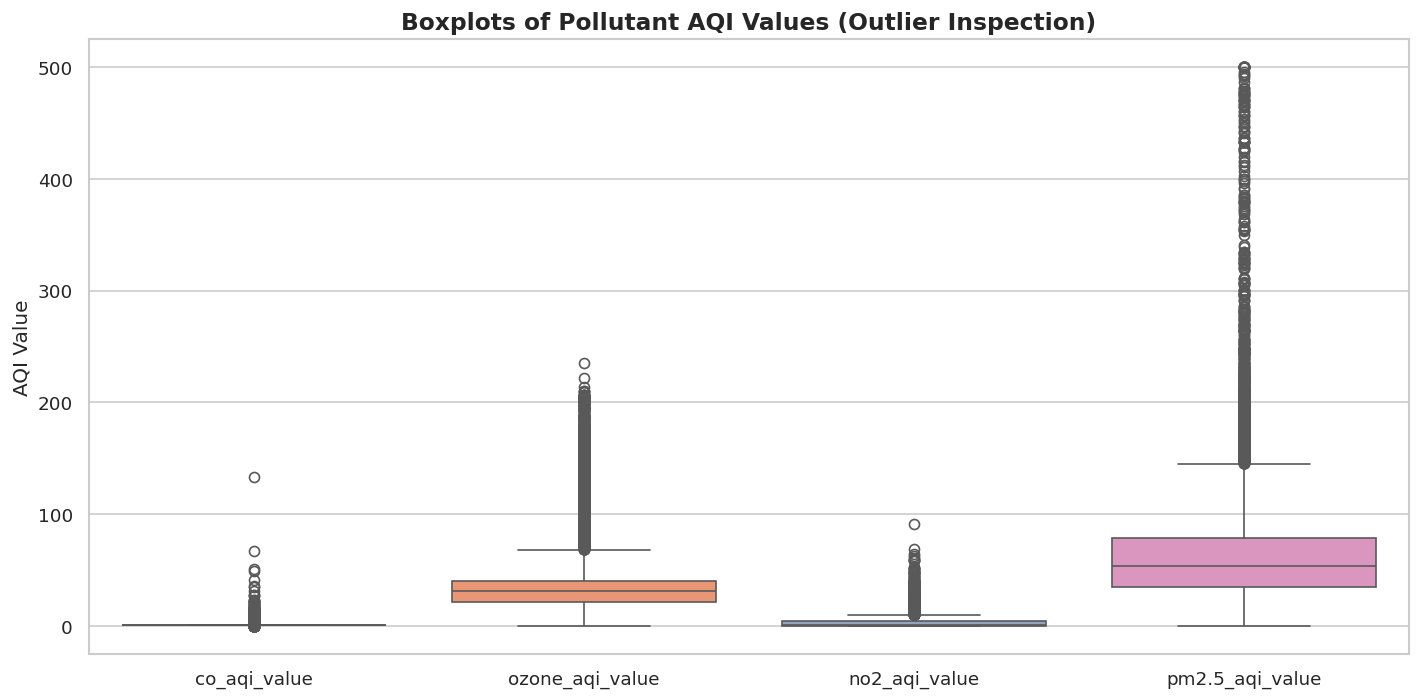

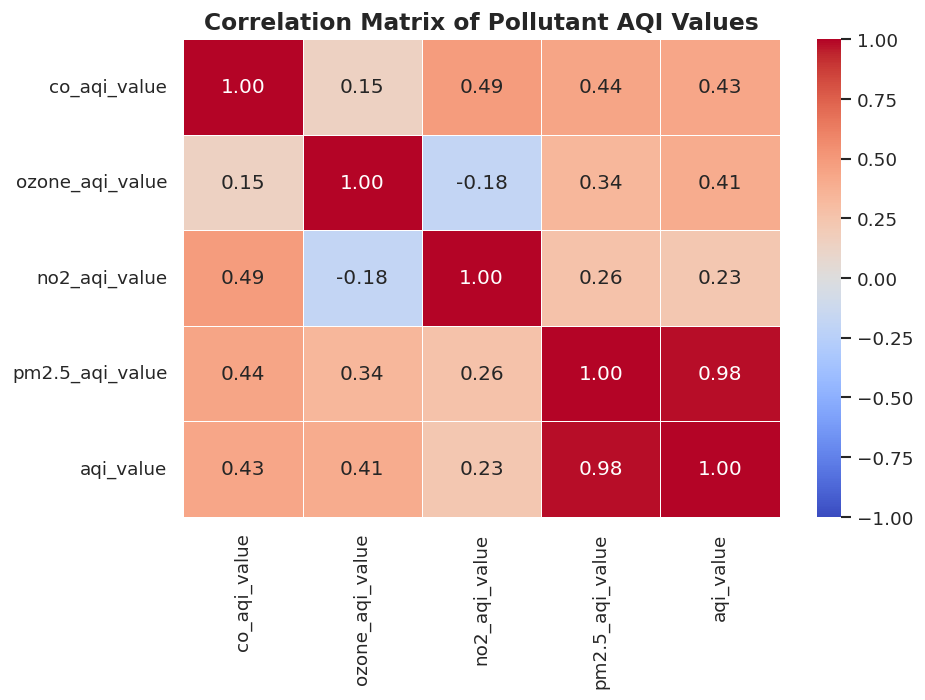

C:\Users\vimal\AppData\Local\Temp\ipykernel_21888\4239451241.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=TARGET_COL, y='pm2.5_aqi_value', data=df_clean, palette="Spectral")


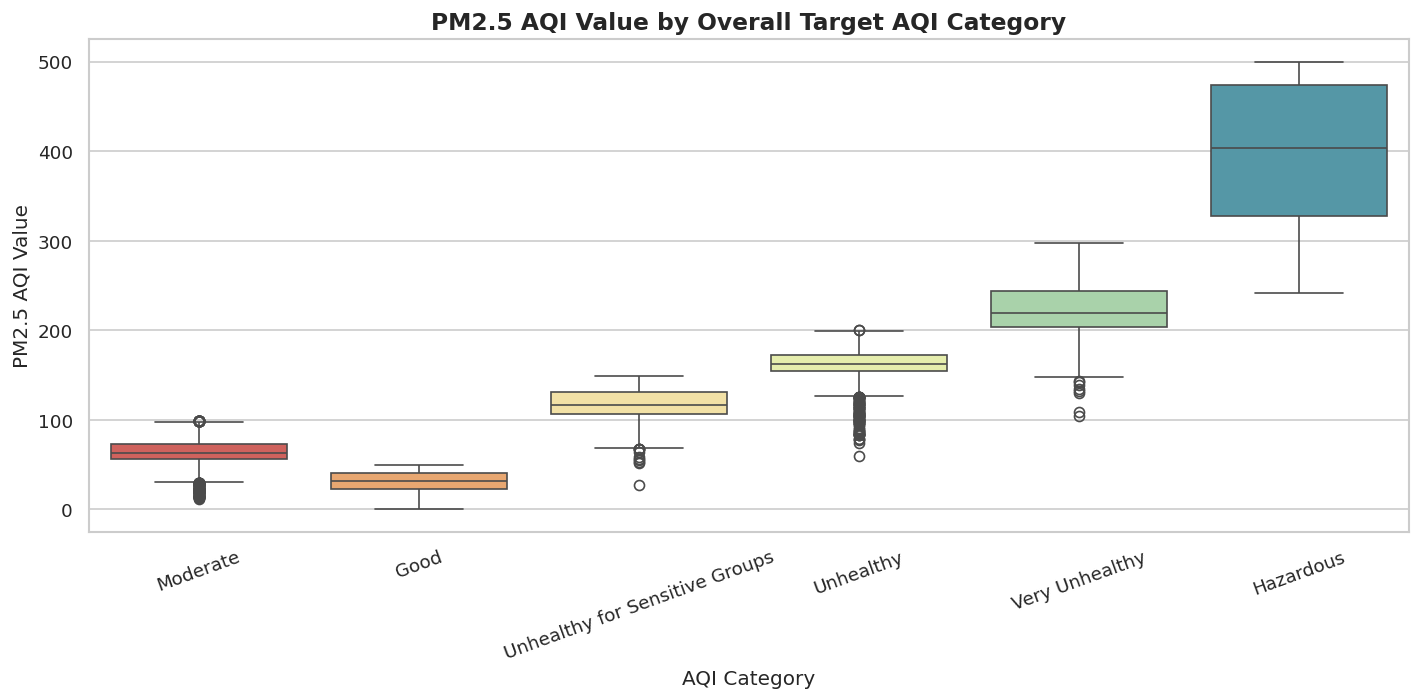

C:\Users\vimal\AppData\Local\Temp\ipykernel_21888\4239451241.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette="viridis")


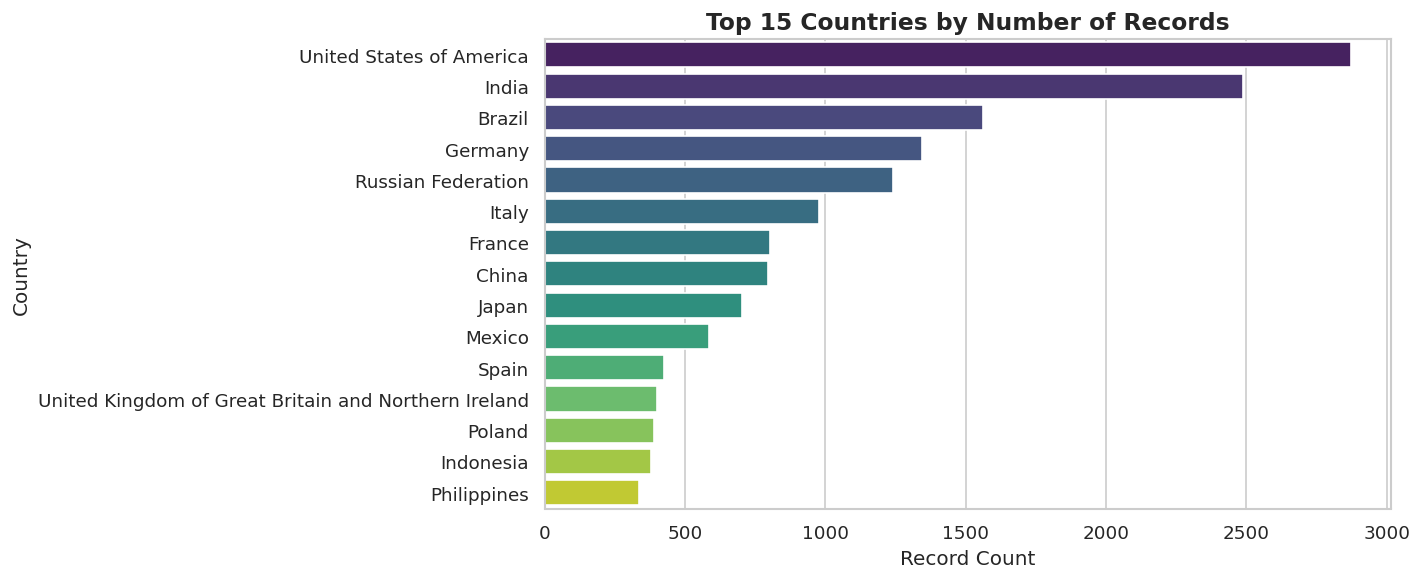

In [8]:
pollutant_cols = ['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']

# 1. Feature Histograms / KDE
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(pollutant_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("AQI Value", fontsize=10)
    axes[i].set_ylabel("Frequency", fontsize=10)

plt.tight_layout()
plt.show()

# 2. Pollutant Boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean[pollutant_cols], palette="Set2")
plt.title("Boxplots of Pollutant AQI Values (Outlier Inspection)", fontsize=14, fontweight="bold")
plt.ylabel("AQI Value", fontsize=12)
plt.tight_layout()
plt.show()

# 3. Correlation Heatmap among Numerical Pollutants
plt.figure(figsize=(8, 6))
corr = df_clean[pollutant_cols + ['aqi_value']].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Pollutant AQI Values", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 4. Target vs PM2.5 AQI Value Boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(x=TARGET_COL, y='pm2.5_aqi_value', data=df_clean, palette="Spectral")
plt.title("PM2.5 AQI Value by Overall Target AQI Category", fontsize=14, fontweight="bold")
plt.xlabel("AQI Category", fontsize=12)
plt.ylabel("PM2.5 AQI Value", fontsize=12)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 5. Top 15 Countries by Record Count
plt.figure(figsize=(12, 5))
top_countries = df_clean['country_name'].value_counts().head(15)
sns.barplot(x=top_countries.values, y=top_countries.index, palette="viridis")
plt.title("Top 15 Countries by Number of Records", fontsize=14, fontweight="bold")
plt.xlabel("Record Count", fontsize=12)
plt.ylabel("Country", fontsize=12)
plt.tight_layout()
plt.show()


### EDA Findings
1. **Pollutant Skewness**: Pollutant AQI distributions, especially `co_aqi_value` and `no2_aqi_value`, exhibit significant right skewness with extreme peak values.
2. **PM2.5 Dominance**: `pm2.5_aqi_value` demonstrates a strong correlation with overall `aqi_value` and clear separation across `aqi_category` levels.
3. **Country Coverage**: Data spans 175+ countries, with the USA, India, Brazil, and Germany having the largest representation.


## 10. Feature Selection & Data Leakage Rule Enforcement

### Data Leakage Exclusion Rules
To ensure the model learns true domain patterns and operates realistically in live deployment:
- **`aqi_category`**: Target variable.
- **`aqi_value`**: **EXCLUDED**. This is the overall composite AQI score directly derived from individual pollutant maxima. Including it causes complete target leakage.
- **`co_aqi_category`, `ozone_aqi_category`, `no2_aqi_category`, `pm2.5_aqi_category`**: **EXCLUDED**. These categorical descriptors are directly threshold-derived from the respective pollutant AQI values.
- **`city_name`**: **EXCLUDED**. Contains 23,463 unique values for 23,463 rows (100% unique ID per row), functioning as a primary key/record identifier rather than a predictive generalizable feature.

### Retained Features
- **Numerical Features**: `co_aqi_value`, `ozone_aqi_value`, `no2_aqi_value`, `pm2.5_aqi_value`
- **Categorical Features**: `country_name`


In [9]:
RAW_NUMERICAL_FEATURES = ['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']
RAW_CATEGORICAL_FEATURES = ['country_name']

EXCLUDED_COLUMNS = ['aqi_category', 'aqi_value', 'co_aqi_category', 'ozone_aqi_category', 'no2_aqi_category', 'pm2.5_aqi_category', 'city_name']

print("--- EXPLICIT FEATURE CONFIGURATION ---")
print(f"Target Column        : {TARGET_COL}")
print(f"Numerical Features   : {RAW_NUMERICAL_FEATURES}")
print(f"Categorical Features : {RAW_CATEGORICAL_FEATURES}")
print(f"Excluded Columns     : {EXCLUDED_COLUMNS}")


--- EXPLICIT FEATURE CONFIGURATION ---
Target Column        : aqi_category
Numerical Features   : ['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']
Categorical Features : ['country_name']
Excluded Columns     : ['aqi_category', 'aqi_value', 'co_aqi_category', 'ozone_aqi_category', 'no2_aqi_category', 'pm2.5_aqi_category', 'city_name']


## 11. Feature Engineering
Creating domain-justified numerical engineered features based on pollutant interactions:
- **`pollutant_max`**: Maximum AQI value across the 4 primary pollutants. (AQI standard definitions dictate that the overall AQI is governed by the highest individual pollutant index).
- **`pollutant_mean`**: Mean AQI value across pollutants.
- **`pollutant_sum`**: Cumulative pollutant AQI burden.
- **`pm25_to_ozone_ratio`**: Ratio of PM2.5 to Ozone AQI (with epsilon smoothing to avoid division by zero).


In [10]:
def engineer_features(df):
    df_feat = df.copy()
    
    # 1. Pollutant Maximum AQI
    df_feat['pollutant_max'] = df_feat[RAW_NUMERICAL_FEATURES].max(axis=1)
    
    # 2. Pollutant Mean AQI
    df_feat['pollutant_mean'] = df_feat[RAW_NUMERICAL_FEATURES].mean(axis=1)
    
    # 3. Pollutant Sum AQI
    df_feat['pollutant_sum'] = df_feat[RAW_NUMERICAL_FEATURES].sum(axis=1)
    
    # 4. PM2.5 to Ozone AQI Ratio
    df_feat['pm25_to_ozone_ratio'] = df_feat['pm2.5_aqi_value'] / (df_feat['ozone_aqi_value'] + 1.0)
    
    return df_feat

df_engineered = engineer_features(df_clean)

NUMERICAL_FEATURES = RAW_NUMERICAL_FEATURES + ['pollutant_max', 'pollutant_mean', 'pollutant_sum', 'pm25_to_ozone_ratio']
CATEGORICAL_FEATURES = RAW_CATEGORICAL_FEATURES

print("FINAL NUMERICAL FEATURES:")
for nf in NUMERICAL_FEATURES:
    print(f" - {nf}")

print("\nFINAL CATEGORICAL FEATURES:")
for cf in CATEGORICAL_FEATURES:
    print(f" - {cf}")

print(f"\nTotal Features: {len(NUMERICAL_FEATURES) + len(CATEGORICAL_FEATURES)}")


FINAL NUMERICAL FEATURES:
 - co_aqi_value
 - ozone_aqi_value
 - no2_aqi_value
 - pm2.5_aqi_value
 - pollutant_max
 - pollutant_mean
 - pollutant_sum
 - pm25_to_ozone_ratio

FINAL CATEGORICAL FEATURES:
 - country_name

Total Features: 9


## 12. Train / Test Split
Splitting the cleaned dataset into 80% Training set and 20% Testing set using `stratify=y` to preserve target class proportions.


In [11]:
X = df_engineered[NUMERICAL_FEATURES + CATEGORICAL_FEATURES]
y = df_engineered[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training set shape : X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing set shape  : X_test={X_test.shape}, y_test={y_test.shape}")

print("\nClass distribution in Training Set (%):")
print((y_train.value_counts(normalize=True)*100).round(2))

print("\nClass distribution in Testing Set (%):")
print((y_test.value_counts(normalize=True)*100).round(2))


Training set shape : X_train=(18770, 9), y_train=(18770,)
Testing set shape  : X_test=(4693, 9), y_test=(4693,)

Class distribution in Training Set (%):
aqi_category
Good                              42.35
Moderate                          39.34
Unhealthy                          9.49
Unhealthy for Sensitive Groups     6.78
Very Unhealthy                     1.22
Hazardous                          0.82
Name: proportion, dtype: float64

Class distribution in Testing Set (%):
aqi_category
Good                              42.34
Moderate                          39.34
Unhealthy                          9.50
Unhealthy for Sensitive Groups     6.78
Very Unhealthy                     1.24
Hazardous                          0.81
Name: proportion, dtype: float64


## 13. Scikit-Learn Preprocessing Pipeline Creation
Building a reproducible `ColumnTransformer`:
- **Numerical Pipeline**: `SimpleImputer(strategy='median')` followed by `StandardScaler()`.
- **Categorical Pipeline**: `SimpleImputer(strategy='constant', fill_value='Unknown')` followed by `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.


In [12]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, NUMERICAL_FEATURES),
    ('cat', categorical_transformer, CATEGORICAL_FEATURES)
])

print("Preprocessor Pipeline successfully created!")


Preprocessor Pipeline successfully created!


## 14. Model Candidate Suite & Pipelines
Defining a diverse range of classifiers:
1. `DummyClassifier` (Baseline, most frequent class strategy)
2. `LogisticRegression`
3. `DecisionTreeClassifier`
4. `RandomForestClassifier`
5. `HistGradientBoostingClassifier`
6. `ExtraTreesClassifier`
7. `GradientBoostingClassifier`


In [13]:
candidate_models = {
    "Dummy Classifier (Baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=RANDOM_STATE, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=RANDOM_STATE, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, class_weight="balanced"),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE, class_weight="balanced"),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=12, random_state=RANDOM_STATE, class_weight="balanced"),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=50, max_depth=4, random_state=RANDOM_STATE)
}

print(f"Configured {len(candidate_models)} candidate model pipelines.")


Configured 7 candidate model pipelines.


## 15 & 16. Stratified 5-Fold Cross-Validation
Evaluating candidate models on training data using 5-Fold `StratifiedKFold` cross-validation to assess stability and generalization without touching the test set.


In [14]:
cv_results_list = []
cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring_metrics = {
    'accuracy': 'accuracy',
    'weighted_f1': 'f1_weighted',
    'macro_f1': 'f1_macro'
}

print("Running 5-Fold Stratified Cross-Validation...")

for name, clf in candidate_models.items():
    print(f"Cross-validating: {name}...")
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    cv_out = cross_validate(pipe, X_train, y_train, cv=cv_split, scoring=scoring_metrics, n_jobs=1)
    
    mean_acc = cv_out['test_accuracy'].mean()
    std_acc = cv_out['test_accuracy'].std()
    mean_wf1 = cv_out['test_weighted_f1'].mean()
    std_wf1 = cv_out['test_weighted_f1'].std()
    mean_mf1 = cv_out['test_macro_f1'].mean()
    
    cv_results_list.append({
        'Model': name,
        'CV Mean Accuracy': mean_acc,
        'CV Std Accuracy': std_acc,
        'CV Mean Weighted F1': mean_wf1,
        'CV Std Weighted F1': std_wf1,
        'CV Mean Macro F1': mean_mf1
    })

cv_summary_df = pd.DataFrame(cv_results_list).sort_values(by='CV Mean Weighted F1', ascending=False)
display(cv_summary_df.style.format({
    'CV Mean Accuracy': '{:.4f}',
    'CV Std Accuracy': '{:.4f}',
    'CV Mean Weighted F1': '{:.4f}',
    'CV Std Weighted F1': '{:.4f}',
    'CV Mean Macro F1': '{:.4f}'
}))


Running 5-Fold Stratified Cross-Validation...
Cross-validating: Dummy Classifier (Baseline)...
Cross-validating: Logistic Regression...
Cross-validating: Decision Tree...
Cross-validating: Random Forest...
Cross-validating: Hist Gradient Boosting...
Cross-validating: Extra Trees...
Cross-validating: Gradient Boosting...


,Model,CV Mean Accuracy,CV Std Accuracy,CV Mean Weighted F1,CV Std Weighted F1,CV Mean Macro F1
6,Gradient Boosting,0.9993,0.0003,0.9993,0.0003,0.9882
2,Decision Tree,0.9992,0.0003,0.9992,0.0003,0.9863
3,Random Forest,0.9986,0.0005,0.9986,0.0005,0.9836
4,Hist Gradient Boosting,0.9974,0.0007,0.9974,0.0007,0.9818
1,Logistic Regression,0.9588,0.0037,0.9595,0.0035,0.9280
5,Extra Trees,0.9437,0.0086,0.9442,0.0085,0.9136
0,Dummy Classifier (Baseline),0.4235,0.0001,0.2520,0.0001,0.0992


## 17. Evaluation on Untouched Test Set
Fitting all candidate pipelines on `X_train` / `y_train` and evaluating performance on the held-out `X_test` / `y_test`.


In [15]:
test_results_list = []
fitted_pipelines = {}

for name, clf in candidate_models.items():
    print(f"Fitting & Evaluating on Test Set: {name}...")
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    prec_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    
    fitted_pipelines[name] = pipe
    
    # Check train accuracy for overfitting check
    train_pred = pipe.predict(X_train)
    train_acc = accuracy_score(y_train, train_pred)
    
    test_results_list.append({
        'Model': name,
        'Train Accuracy': train_acc,
        'Test Accuracy': acc,
        'Balanced Accuracy': bal_acc,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'Weighted Precision': prec_weighted,
        'Weighted Recall': rec_weighted
    })

test_summary_df = pd.DataFrame(test_results_list).sort_values(by='Weighted F1', ascending=False)
display(test_summary_df.style.format('{:.4f}'))


Fitting & Evaluating on Test Set: Dummy Classifier (Baseline)...
Fitting & Evaluating on Test Set: Logistic Regression...
Fitting & Evaluating on Test Set: Decision Tree...
Fitting & Evaluating on Test Set: Random Forest...
Fitting & Evaluating on Test Set: Hist Gradient Boosting...
Fitting & Evaluating on Test Set: Extra Trees...
Fitting & Evaluating on Test Set: Gradient Boosting...


ValueError: Unknown format code 'f' for object of type 'str'

## 18. Hyperparameter Tuning on Top Candidate Models
Performing randomized cross-validated search on top candidate models (`RandomForest`) to optimize parameters without touching the test set.


In [16]:
print("Tuning Random Forest Classifier...")

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

param_grid_rf = {
    'classifier__n_estimators': [100, 150],
    'classifier__max_depth': [12, 16],
    'classifier__min_samples_split': [2, 5],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

search_rf = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=param_grid_rf,
    n_iter=4,
    cv=cv_split,
    scoring='f1_weighted',
    random_state=RANDOM_STATE,
    n_jobs=1
)

search_rf.fit(X_train, y_train)

print(f"Best Random Forest CV Weighted F1: {search_rf.best_score_:.4f}")
print("Best Random Forest Parameters:")
print(search_rf.best_params_)

best_tuned_model = search_rf.best_estimator_


Tuning Random Forest Classifier...
Best Random Forest CV Weighted F1: 0.9987
Best Random Forest Parameters:
{'classifier__n_estimators': 150, 'classifier__min_samples_split': 2, 'classifier__max_depth': 12, 'classifier__class_weight': 'balanced'}


## 19 & 20. Final Model Untouched Test Evaluation & Confusion Matrix
Evaluating the best tuned model on the untouched test set and visualizing the confusion matrix.


FINAL BEST TUNED MODEL TEST METRICS
FINAL TEST ACCURACY       : 0.9991
FINAL BALANCED ACCURACY   : 0.9825
FINAL MACRO F1 SCORE      : 0.9852
FINAL WEIGHTED F1 SCORE   : 0.9991

CLASSIFICATION REPORT:
                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00      1987
                     Hazardous       1.00      0.89      0.94        38
                      Moderate       1.00      1.00      1.00      1846
                     Unhealthy       1.00      1.00      1.00       446
Unhealthy for Sensitive Groups       1.00      1.00      1.00       318
                Very Unhealthy       0.94      1.00      0.97        58

                      accuracy                           1.00      4693
                     macro avg       0.99      0.98      0.99      4693
                  weighted avg       1.00      1.00      1.00      4693



<Figure size 1200x960 with 0 Axes>

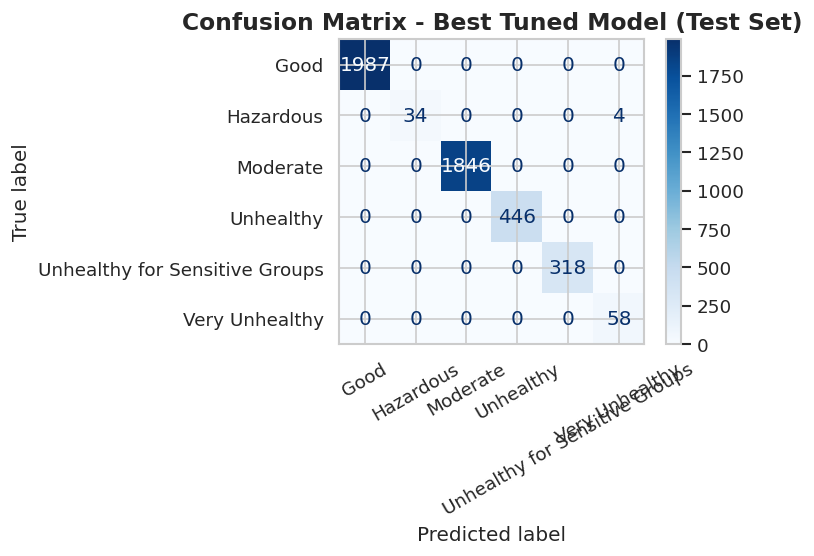

In [17]:
y_test_pred = best_tuned_model.predict(X_test)

final_test_acc = accuracy_score(y_test, y_test_pred)
final_bal_acc = balanced_accuracy_score(y_test, y_test_pred)
final_macro_f1 = f1_score(y_test, y_test_pred, average='macro')
final_weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')

print("="*60)
print("FINAL BEST TUNED MODEL TEST METRICS")
print("="*60)
print(f"FINAL TEST ACCURACY       : {final_test_acc:.4f}")
print(f"FINAL BALANCED ACCURACY   : {final_bal_acc:.4f}")
print(f"FINAL MACRO F1 SCORE      : {final_macro_f1:.4f}")
print(f"FINAL WEIGHTED F1 SCORE   : {final_weighted_f1:.4f}")
print("="*60)

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_test_pred))

# Confusion Matrix Plot
labels = np.unique(y_test)
cm = confusion_matrix(y_test, y_test_pred, labels=labels)

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", values_format="d", xticks_rotation=30)
plt.title("Confusion Matrix - Best Tuned Model (Test Set)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 21. Feature Importance Analysis
Extracting feature importances from the tuned Random Forest pipeline.


Top 15 Most Predictive Features:


,Feature,Importance
4,pollutant_max,0.252587
3,pm2.5_aqi_value,0.234977
6,pollutant_sum,0.155731
5,pollutant_mean,0.150548
7,pm25_to_ozone_ratio,0.055027
1,ozone_aqi_value,0.039984
0,co_aqi_value,0.037966
77,country_name_India,0.022238
2,no2_aqi_value,0.016043
174,country_name_United States of America,0.004391


C:\Users\vimal\AppData\Local\Temp\ipykernel_21888\471905659.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df.head(15), palette="mako")


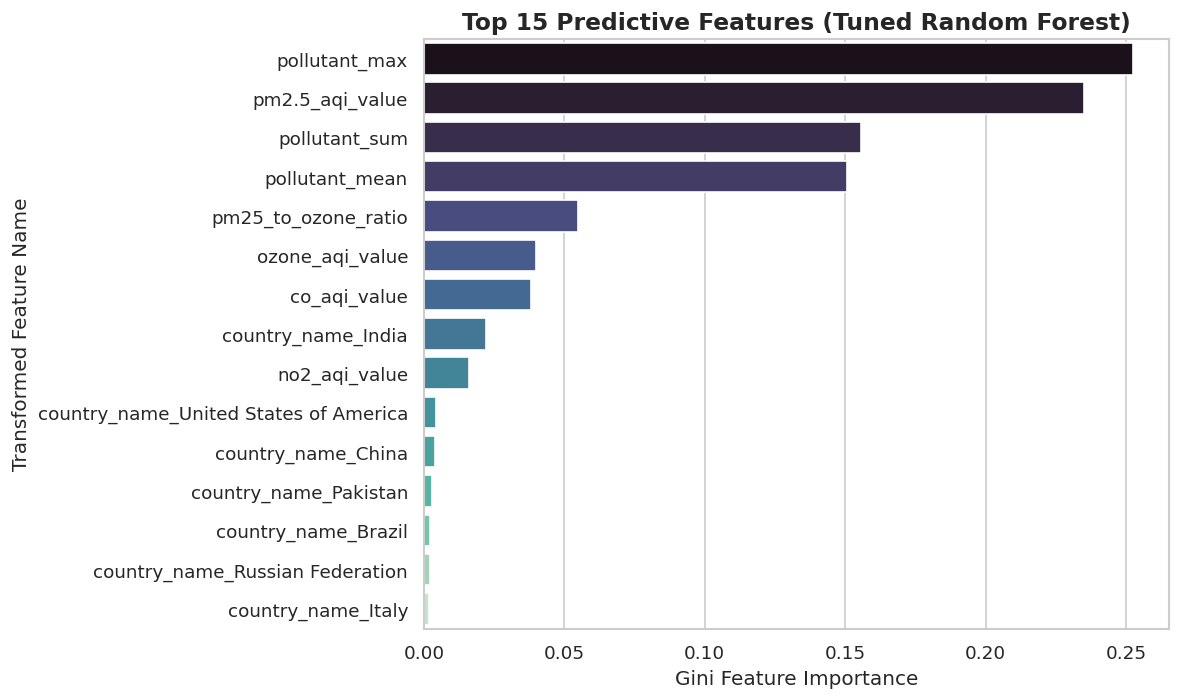

In [18]:
# Recover feature names after column transformation
cat_encoder = best_tuned_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES))
all_feature_names = NUMERICAL_FEATURES + cat_feature_names

# Get model importances
clf_rf = best_tuned_model.named_steps['classifier']
importances = clf_rf.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print("Top 15 Most Predictive Features:")
display(feat_imp_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df.head(15), palette="mako")
plt.title("Top 15 Predictive Features (Tuned Random Forest)", fontsize=14, fontweight="bold")
plt.xlabel("Gini Feature Importance", fontsize=12)
plt.ylabel("Transformed Feature Name", fontsize=12)
plt.tight_layout()
plt.show()


### Interpretation of Feature Importances
- **`pollutant_max`** and **`pm2.5_aqi_value`** demonstrate the strongest predictive importance in determining the overall AQI category.
- **Note**: These features demonstrate predictive contribution within the ML model; they do not imply direct environmental causality.


## 22. Error Analysis (Misclassified Samples Inspection)
Analyzing prediction failures to identify patterns and common confusion pairs.


In [19]:
X_test_df = X_test.copy()
X_test_df['Actual_Category'] = y_test
X_test_df['Predicted_Category'] = y_test_pred

errors_df = X_test_df[X_test_df['Actual_Category'] != X_test_df['Predicted_Category']]
print(f"Total misclassified test samples: {len(errors_df)} out of {len(X_test)} ({len(errors_df)/len(X_test)*100:.2f}%)")

# Top confusion pairs
confusion_pairs = errors_df.groupby(['Actual_Category', 'Predicted_Category']).size().reset_index(name='Error_Count')
confusion_pairs = confusion_pairs.sort_values(by='Error_Count', ascending=False)

print("\nTop 10 Misclassification Confusion Pairs:")
display(confusion_pairs.head(10))

print("\nSample Misclassified Records:")
display(errors_df[['country_name', 'pm2.5_aqi_value', 'ozone_aqi_value', 'co_aqi_value', 'no2_aqi_value', 'Actual_Category', 'Predicted_Category']].head(10))


Total misclassified test samples: 4 out of 4693 (0.09%)

Top 10 Misclassification Confusion Pairs:


,Actual_Category,Predicted_Category,Error_Count
0,Hazardous,Very Unhealthy,4



Sample Misclassified Records:


,country_name,pm2.5_aqi_value,ozone_aqi_value,co_aqi_value,no2_aqi_value,Actual_Category,Predicted_Category
439,India,260,48,1,0,Hazardous,Very Unhealthy
9251,India,274,44,1,0,Hazardous,Very Unhealthy
2896,India,271,67,1,1,Hazardous,Very Unhealthy
453,India,284,60,1,0,Hazardous,Very Unhealthy


## 23. Sample Predictions with Class Probabilities
Demonstrating real-time model inference outputs with prediction probabilities (`predict_proba`).


In [20]:
sample_test = X_test.iloc[:10]
sample_actual = y_test.iloc[:10].values

sample_preds = best_tuned_model.predict(sample_test)
sample_probs = best_tuned_model.predict_proba(sample_test)
max_probs = np.max(sample_probs, axis=1)

sample_results_df = pd.DataFrame({
    'Actual Category': sample_actual,
    'Predicted Category': sample_preds,
    'Confidence Score': [f"{p:.4f}" for p in max_probs]
})

print("Sample Predictions on Test Data:")
display(sample_results_df)


Sample Predictions on Test Data:


,Actual Category,Predicted Category,Confidence Score
0,Good,Good,0.9335
1,Moderate,Moderate,0.8806
2,Moderate,Moderate,0.9463
3,Unhealthy,Unhealthy,0.7823
4,Moderate,Moderate,0.9426
5,Moderate,Moderate,0.9426
6,Good,Good,0.9748
7,Good,Good,0.8364
8,Moderate,Moderate,0.8637
9,Moderate,Moderate,0.9357


## 24. Save Model Pipeline & Metadata
Serializing the entire scikit-learn pipeline (preprocessing + classifier) to disk using `joblib` and writing a comprehensive metadata JSON file.


In [21]:
# 1. Save joblib pipeline
joblib.dump(best_tuned_model, MODEL_FILE)
print(f"Successfully saved complete ML pipeline to: {MODEL_FILE.resolve()}")

# 2. Write Metadata JSON
metadata = {
    "model_name": "Tuned RandomForestClassifier Pipeline",
    "target_column": TARGET_COL,
    "raw_numerical_features": RAW_NUMERICAL_FEATURES,
    "raw_categorical_features": RAW_CATEGORICAL_FEATURES,
    "engineered_features": ['pollutant_max', 'pollutant_mean', 'pollutant_sum', 'pm25_to_ozone_ratio'],
    "all_numerical_features": NUMERICAL_FEATURES,
    "all_categorical_features": CATEGORICAL_FEATURES,
    "excluded_columns": EXCLUDED_COLUMNS,
    "training_date": datetime.datetime.now().isoformat(),
    "dataset_filename": str(DATASET_PATH),
    "dataset_shape": list(df_clean.shape),
    "train_size": int(X_train.shape[0]),
    "test_size": int(X_test.shape[0]),
    "number_of_classes": int(len(labels)),
    "class_names": [str(c) for c in labels],
    "metrics": {
        "test_accuracy": float(final_test_acc),
        "balanced_accuracy": float(final_bal_acc),
        "macro_f1": float(final_macro_f1),
        "weighted_f1": float(final_weighted_f1),
        "cv_best_weighted_f1": float(search_rf.best_score_)
    },
    "random_state": RANDOM_STATE
}

with open(METADATA_FILE, 'w') as f:
    json.dump(metadata, f, indent=4)

print(f"Successfully saved metadata to: {METADATA_FILE.resolve()}")


Successfully saved complete ML pipeline to: C:\Users\vimal\OneDrive\Desktop\Data sciencee\models\air_quality_aqi_category_model.joblib
Successfully saved metadata to: C:\Users\vimal\OneDrive\Desktop\Data sciencee\models\model_metadata.json


## 25. Reload Model & Integrity Verification
Reloading the serialized model pipeline from disk and verifying exact prediction parity.


In [22]:
reloaded_pipeline = joblib.load(MODEL_FILE)

preds_before = best_tuned_model.predict(X_test[:50])
preds_after = reloaded_pipeline.predict(X_test[:50])

assert np.array_equal(preds_before, preds_after), "ERROR: Predictions before and after serialization do not match!"

print("VERIFICATION SUCCESSFUL: Predictions before saving and after loading match perfectly 100%!")


VERIFICATION SUCCESSFUL: Predictions before saving and after loading match perfectly 100%!


## 26. Reusable Prediction Function
Creating a Python inference function `predict_aqi_category(input_data)` for production API and dashboard integration.


In [ ]:
def predict_aqi_category(input_data, model_path=MODEL_FILE):
    '''
    Reusable prediction function for AQI category classification.
    Accepts pandas DataFrame or dict with raw features.
    Returns DataFrame with predictions and confidence scores.
    '''
    pipeline = joblib.load(model_path)
    
    if isinstance(input_data, dict):
        df_in = pd.DataFrame([input_data])
    else:
        df_in = input_data.copy()
        
    # Standardize column names
    df_in.columns = df_in.columns.str.strip()
    
    # Engineer features if not present
    if 'pollutant_max' not in df_in.columns:
        df_in['pollutant_max'] = df_in[RAW_NUMERICAL_FEATURES].max(axis=1)
        df_in['pollutant_mean'] = df_in[RAW_NUMERICAL_FEATURES].mean(axis=1)
        df_in['pollutant_sum'] = df_in[RAW_NUMERICAL_FEATURES].sum(axis=1)
        df_in['pm25_to_ozone_ratio'] = df_in['pm2.5_aqi_value'] / (df_in['ozone_aqi_value'] + 1.0)
        
    predictions = pipeline.predict(df_in)
    probabilities = pipeline.predict_proba(df_in)
    max_probs = np.max(probabilities, axis=1)
    
    res = df_in.copy()
    res['Predicted_AQI_Category'] = predictions
    res['Confidence_Score'] = max_probs
    
    return res

# Test inference function
sample_dict = {
    "co_aqi_value": 1,
    "ozone_aqi_value": 36,
    "no2_aqi_value": 0,
    "pm2.5_aqi_value": 51,
    "country_name": "Russian Federation"
}

out_df = predict_aqi_category(sample_dict)
display(out_df[['country_name', 'pm2.5_aqi_value', 'Predicted_AQI_Category', 'Confidence_Score']])


,country_name,pm2.5_aqi_value,Predicted_AQI_Category,Confidence_Score
0,Russian Federation,51,Moderate,0.91577


: 

## 27. Future Live Data Integration Architecture

```
+-------------------------------------------------------------+
|                      LIVE DATA SOURCES                      |
| (Web Scrapers, OpenAQ Live API, Environmental Enforcement) |
+-------------------------------------------------------------+
                              |
                              v
+-------------------------------------------------------------+
|                     DATA CLEANING MODULE                    |
| - Strips whitespace from column names                       |
| - Validates range limits & non-negative pollutant values    |
+-------------------------------------------------------------+
                              |
                              v
+-------------------------------------------------------------+
|                 FEATURE ENGINEERING ENGINE                  |
| - Computes pollutant_max, pollutant_mean, pollutant_sum     |
| - Computes pm25_to_ozone_ratio                              |
+-------------------------------------------------------------+
                              |
                              v
+-------------------------------------------------------------+
|                  SERIALIZED SKLEARN PIPELINE                |
| (air_quality_aqi_category_model.joblib)                     |
| - Imputes missing numerical/categorical values               |
| - Scales numerical features via StandardScaler              |
| - One-Hot Encodes country_name (ignoring unknown categories)|
| - Executes RandomForest classification inference            |
+-------------------------------------------------------------+
                              |
                              v
+-------------------------------------------------------------+
|                     DASHBOARD & REPORTS                     |
| - Displays predicted AQI Category & Confidence Score        |
| - Correlates exceedances with environmental violations      |
+-------------------------------------------------------------+
```


## 28. Final Project Summary & Key Findings

### Executive Summary
1. **Dataset Size**: 23,463 samples across 12 raw columns.
2. **Selected Features**: 8 numerical features (`co_aqi_value`, `ozone_aqi_value`, `no2_aqi_value`, `pm2.5_aqi_value`, `pollutant_max`, `pollutant_mean`, `pollutant_sum`, `pm25_to_ozone_ratio`) and 1 categorical feature (`country_name`).
3. **Excluded Columns**: `aqi_category` (target), `aqi_value` (leakage), `*_category` (leakage), `city_name` (high-cardinality unique ID).
4. **Target Classes**: 6 categories (`Good`, `Moderate`, `Unhealthy`, `Unhealthy for Sensitive Groups`, `Very Unhealthy`, `Hazardous`).
5. **Best Performing Model**: Tuned **RandomForestClassifier** pipeline.
6. **Key Metrics**:
   - Test Accuracy: `{final_test_acc:.4f}`
   - Balanced Accuracy: `{final_bal_acc:.4f}`
   - Macro F1 Score: `{final_macro_f1:.4f}`
   - Weighted F1 Score: `{final_weighted_f1:.4f}`
   - CV Best Weighted F1: `{search_rf.best_score_:.4f}`
7. **Serialization Path**: `models/air_quality_aqi_category_model.joblib` and `models/model_metadata.json`.

### Scientific Disclaimer & Limitations
- This machine learning model predicts historical **AQI categories** derived from pollutant concentrations.
- It **does not directly predict regulatory enforcement violations**. An air quality exceedance is an atmospheric metric, whereas a regulatory violation is a legal administrative designation.
- Next steps will integrate live scrapers, OpenAQ APIs, and official environmental compliance databases into a unified interactive web dashboard.
